In [1]:
# imports
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

In [ ]:
# import data
df = pd.read_csv('csv/play_data.csv')
df = df.drop(columns = ['Unnamed: 0'])
df.columns

Index(['play_id', 'half_seconds_remaining', 'down', 'goal_to_go', 'ydstogo',
       'yardline_100', 'play_type', 'posteam_score', 'defteam_score', 'run'],
      dtype='object')

In [ ]:
df

,play_id,half_seconds_remaining,down,goal_to_go,ydstogo,yardline_100,play_type,posteam_score,defteam_score,run
0,63.0,1796.0,1.0,0,10.0,78.0,run,0.0,0.0,1
1,85.0,1758.0,2.0,0,7.0,75.0,pass,0.0,0.0,0
2,115.0,1720.0,1.0,0,10.0,64.0,pass,0.0,0.0,0
3,135.0,1677.0,2.0,0,21.0,75.0,run,0.0,0.0,1
4,166.0,1634.0,3.0,0,23.0,77.0,run,0.0,0.0,1
...,...,...,...,...,...,...,...,...,...,...
4685,4510.0,377.0,2.0,0,6.0,74.0,pass,17.0,17.0,0
4686,4570.0,321.0,1.0,0,10.0,47.0,run,17.0,17.0,1
4687,4632.0,298.0,2.0,0,6.0,43.0,pass,17.0,17.0,0
4688,4655.0,294.0,3.0,0,6.0,43.0,pass,17.0,17.0,0


In [ ]:
# Goal: predict if a play is a run (1) or a pass (0) from the game situation
X = df[['half_seconds_remaining', 'down', 'ydstogo', 'yardline_100', 'posteam_score', 'defteam_score']]
y = df['run']

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
# KNN = look at the K most similar plays from the training data and let them vote
# n_neighbors = K, how many similar plays get a vote
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Always guessing pass:", 1 - y_test.mean())

Accuracy: 0.5522388059701493
Always guessing pass: 0.570362473347548


In [ ]:
# "Similar" means close in distance, but our columns are on very different scales
# half_seconds_remaining goes up to 1800 while down only goes up to 4 so time dominates the distance
X_train.describe().loc[['min', 'max']]

,half_seconds_remaining,down,ydstogo,yardline_100,posteam_score,defteam_score
min,3.0,1.0,1.0,1.0,0.0,0.0
max,1800.0,4.0,34.0,99.0,52.0,52.0


In [8]:
# Fix: scale every column so they have a mean of 0 and a similar spread
# fit the scaler on the training data only, then use it to transform both (why not fit on the test data too?)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train_scaled, y_train)

y_pred = model.predict(X_test_scaled)
print("Scaled Accuracy:", accuracy_score(y_test, y_pred))

Scaled Accuracy: 0.6364605543710021


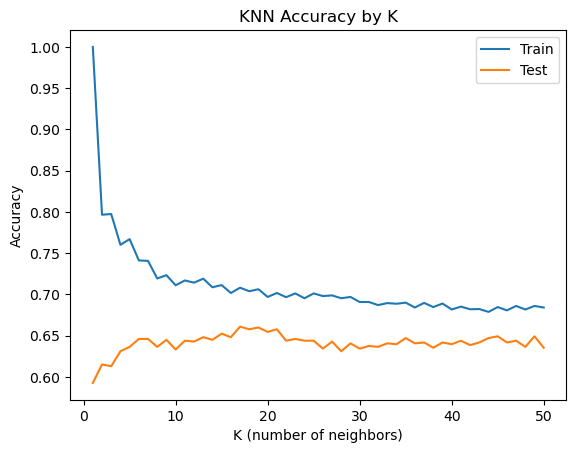

In [9]:
# How do we pick K? Try a bunch and compare train vs test accuracy
# small K = follows the training data too closely (overfits), big K = too blurry
ks = range(1, 51)
train_acc = []
test_acc = []

for k in ks:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    train_acc.append(accuracy_score(y_train, knn.predict(X_train_scaled)))
    test_acc.append(accuracy_score(y_test, knn.predict(X_test_scaled)))

plt.plot(ks, train_acc, label='Train')
plt.plot(ks, test_acc, label='Test')
plt.xlabel('K (number of neighbors)')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy by K')
plt.legend()
plt.show()

In [10]:
# Refit with the K that did best on the test data
best_k = list(ks)[test_acc.index(max(test_acc))]
print("Best K:", best_k)

model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n ", classification_report(y_test, y_pred, target_names=['Pass', 'Run']))

Best K: 17
Accuracy: 0.6609808102345416

Classification Report:
                precision    recall  f1-score   support

        Pass       0.67      0.80      0.73       535
         Run       0.64      0.48      0.55       403

    accuracy                           0.66       938
   macro avg       0.66      0.64      0.64       938
weighted avg       0.66      0.66      0.65       938



In [11]:
# Predict a new play: 3rd & 1 on the opponent's 40, 5 minutes left in the half, tied 14-14
new_play = pd.DataFrame({
    'half_seconds_remaining': [300],
    'down': [3],
    'ydstogo': [1],
    'yardline_100': [40],
    'posteam_score': [14],
    'defteam_score': [14]
})
new_scaled = scaler.transform(new_play[X.columns])

print("Prediction:", 'Run' if model.predict(new_scaled)[0] == 1 else 'Pass')
print("Run probability:", model.predict_proba(new_scaled)[0][1].round(2))

Prediction: Run
Run probability: 0.53


In [12]:
# Who were the neighbors that voted? These are the most similar plays the model has seen
distances, indices = model.kneighbors(new_scaled)
neighbors = X_train.iloc[indices[0]].copy()
neighbors['run'] = y_train.iloc[indices[0]].values
neighbors['distance'] = distances[0].round(2)
neighbors

,half_seconds_remaining,down,ydstogo,yardline_100,posteam_score,defteam_score,run,distance
3297,550.0,3.0,2.0,41.0,14.0,14.0,1,0.51
1255,214.0,3.0,1.0,29.0,16.0,10.0,1,0.65
1120,320.0,3.0,1.0,40.0,20.0,17.0,1,0.67
3300,240.0,3.0,2.0,25.0,14.0,14.0,1,0.69
1942,484.0,3.0,3.0,52.0,13.0,14.0,1,0.78
2782,48.0,3.0,2.0,52.0,17.0,14.0,0,0.78
119,85.0,3.0,1.0,49.0,13.0,20.0,0,0.79
2946,12.0,3.0,2.0,45.0,10.0,10.0,0,0.82
2993,27.0,3.0,1.0,28.0,10.0,17.0,0,0.86
2214,66.0,3.0,1.0,46.0,7.0,15.0,0,0.87
